In [1]:
!nvidia-smi

Fri Oct 30 21:51:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
print(os.listdir('/content/drive/MyDrive/airi_helmet'))

['raw', 'outputs', 'extra_test']


In [5]:
ROOT = '/content/drive/MyDrive/airi_helmet'
!rm -rf /content/rf && mkdir -p /content/rf
!unzip -q "{ROOT}/roboflow_export.zip" -d /content/rf
!ls /content/rf
!cat /content/rf/data.yaml

replace /content/rf/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
data.yaml  README.roboflow.txt	test  train  valid
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['helmet', 'no_helmet', 'person']

roboflow:
  workspace: airiintern
  project: helmet-detection-fgant
  version: 1
  license: Private
  url: https://app.roboflow.com/airiintern/helmet-detection-fgant/1

In [6]:
import os, glob, shutil
OUT = f'{ROOT}/dataset'
if os.path.exists(OUT):
    shutil.rmtree(OUT)
for rf, ours in [('train', 'train'), ('valid', 'val'), ('test', 'test')]:
    os.makedirs(f'{OUT}/images/{ours}')
    os.makedirs(f'{OUT}/labels/{ours}')
    for f in glob.glob(f'/content/rf/{rf}/images/*'):
        shutil.copy(f, f'{OUT}/images/{ours}')
    for f in glob.glob(f'/content/rf/{rf}/labels/*.txt'):
        shutil.copy(f, f'{OUT}/labels/{ours}')
    print(ours, 'images:', len(os.listdir(f'{OUT}/images/{ours}')), 'labels:', len(os.listdir(f'{OUT}/labels/{ours}')))

train images: 157 labels: 157
val images: 45 labels: 45
test images: 22 labels: 22


In [7]:
!pip install -q ultralytics
import shutil, os, yaml, time, torch

shutil.rmtree('/content/dataset', ignore_errors=True)
shutil.copytree(f'{ROOT}/dataset', '/content/dataset')

CLASS_NAMES = ['helmet', 'no_helmet', 'person']
cfg = {'path': '/content/dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test',
       'nc': 3, 'names': {i: n for i, n in enumerate(CLASS_NAMES)}}
yaml.safe_dump(cfg, open('/content/data.yaml', 'w'), sort_keys=False)
shutil.copy('/content/data.yaml', f'{ROOT}/data.yaml')   # backup copy for your submission

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print('GPU used:', GPU_NAME)
print(open('/content/data.yaml').read())

GPU used: Tesla T4
path: /content/dataset
train: images/train
val: images/val
test: images/test
nc: 3
names:
  0: helmet
  1: no_helmet
  2: person



In [8]:
from ultralytics import YOLO

EPOCHS, IMGSZ, BATCH = 50, 640, 16
model = YOLO('yolov8n.pt')

t0 = time.time()
results = model.train(data='/content/data.yaml', epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                      patience=20, project='/content/runs', name='helmet_v8n', exist_ok=True, seed=42, plots=True)
train_secs = time.time() - t0
print(f'Training time: {train_secs/60:.1f} min | GPU: {GPU_NAME} | epochs={EPOCHS} imgsz={IMGSZ} batch={BATCH}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, 

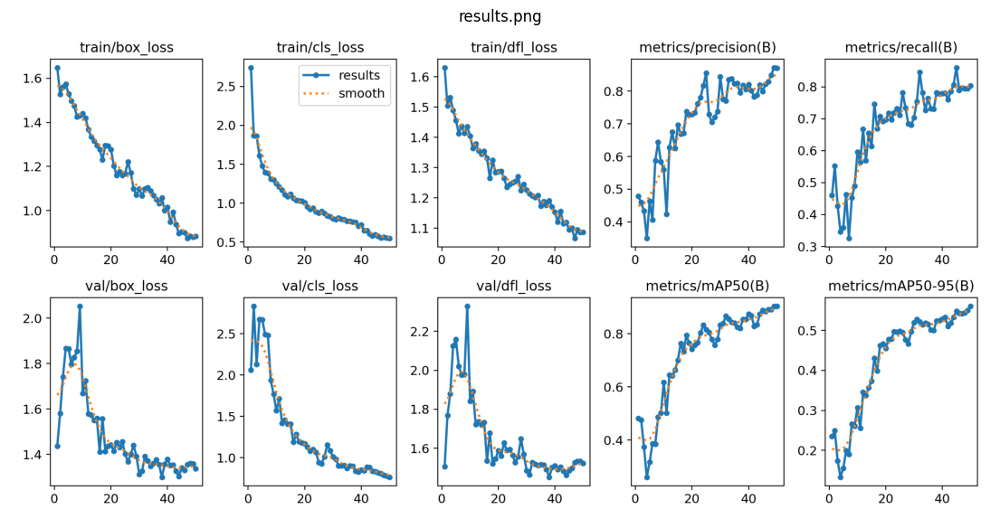

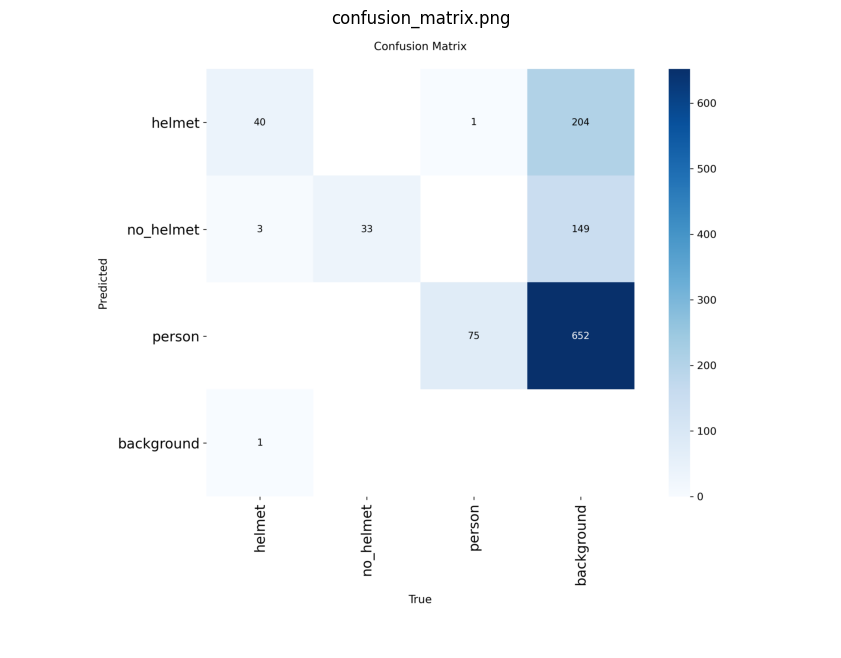

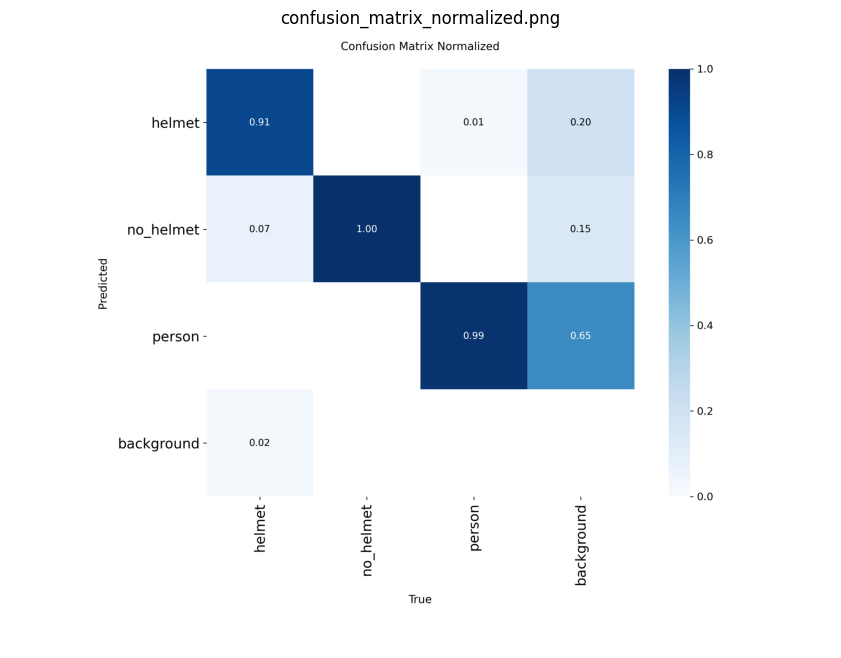

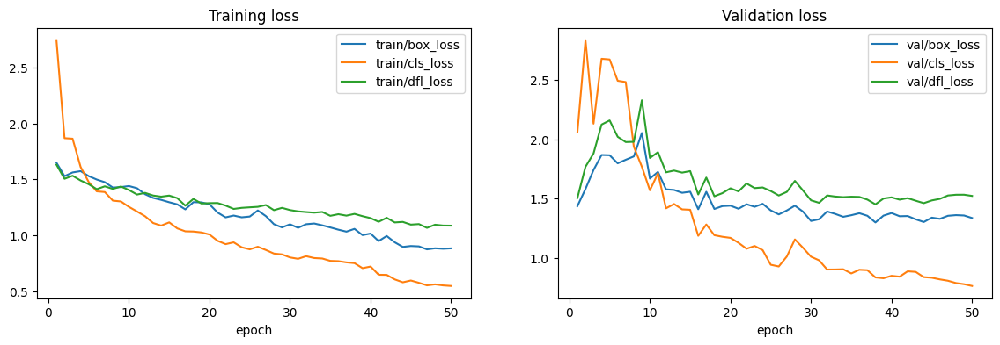

In [9]:
import matplotlib.pyplot as plt, pandas as pd, os
RUN = '/content/runs/helmet_v8n'
for f in ['results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'PR_curve.png']:
    p = f'{RUN}/{f}'
    if os.path.exists(p):
        plt.figure(figsize=(14, 8)); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(f); plt.show()

res_df = pd.read_csv(f'{RUN}/results.csv'); res_df.columns = [c.strip() for c in res_df.columns]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k in ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']:
    ax[0].plot(res_df['epoch'], res_df[k], label=k)
ax[0].set_title('Training loss'); ax[0].legend(); ax[0].set_xlabel('epoch')
for k in ['val/box_loss', 'val/cls_loss', 'val/dfl_loss']:
    ax[1].plot(res_df['epoch'], res_df[k], label=k)
ax[1].set_title('Validation loss'); ax[1].legend(); ax[1].set_xlabel('epoch')
plt.show()

In [10]:
best = YOLO(f'{RUN}/weights/best.pt')

def eval_split(split):
    m = best.val(data='/content/data.yaml', split=split, imgsz=640, project='/content/runs',
                 name=f'eval_{split}', exist_ok=True, plots=True)
    rows = [{'class': 'ALL', 'precision': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map}]
    for i, c in enumerate(m.box.ap_class_index):
        rows.append({'class': m.names[int(c)], 'precision': m.box.p[i], 'recall': m.box.r[i],
                     'mAP50': m.box.ap50[i], 'mAP50-95': m.box.ap[i]})
    return pd.DataFrame(rows).round(3)

val_table = eval_split('val');   print('VALIDATION'); display(val_table)
test_table = eval_split('test'); print('TEST'); display(test_table)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2279.2±553.3 MB/s, size: 64.3 KB)
val: Scanning /content/dataset/labels/val.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 13.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.0it/s 2.9s
                   all         45        153       0.87      0.803      0.902      0.557
                helmet         26         44      0.876      0.805      0.898       0.61
             no_helmet         21         33      0.871      0.816      0.916      0.594
                person         45         76      0.863      0.789      0.892      0.468
Speed: 16.9ms preprocess, 14.6ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/eval_val
VALIDATION


,class,precision,recall,mAP50,mAP50-95
0,ALL,0.870,0.803,0.902,0.557
1,helmet,0.876,0.805,0.898,0.610
2,no_helmet,0.871,0.816,0.916,0.594
3,person,0.863,0.789,0.892,0.468


Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2195.2±772.4 MB/s, size: 66.4 KB)
val: Scanning /content/dataset/labels/test... 22 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22 1.8Kit/s 0.0s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.3it/s 0.9s
                   all         22         97      0.761      0.757      0.794      0.487
                helmet         10         28      0.761      0.684       0.74      0.446
             no_helmet         15         23      0.856      0.913      0.918      0.696
                person         22         46      0.666      0.674      0.725       0.32
Speed: 5.3ms preprocess, 11.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results 

,class,precision,recall,mAP50,mAP50-95
0,ALL,0.761,0.757,0.794,0.487
1,helmet,0.761,0.684,0.740,0.446
2,no_helmet,0.856,0.913,0.918,0.696
3,person,0.666,0.674,0.725,0.320


22 test images

0: 640x640 1 helmet, 3 persons, 5.1ms
1: 640x640 1 helmet, 1 person, 5.1ms
2: 640x640 1 helmet, 1 person, 5.1ms
3: 640x640 1 helmet, 1 person, 5.1ms
4: 640x640 3 helmets, 2 persons, 5.1ms
5: 640x640 1 helmet, 2 persons, 5.1ms
6: 640x640 3 helmets, 3 no_helmets, 4 persons, 5.1ms
7: 640x640 5 helmets, 4 no_helmets, 11 persons, 5.1ms
8: 640x640 6 helmets, 1 no_helmet, 4 persons, 5.1ms
9: 640x640 4 helmets, 1 no_helmet, 5 persons, 5.1ms
10: 640x640 1 no_helmet, 1 person, 5.1ms
11: 640x640 1 no_helmet, 1 person, 5.1ms
12: 640x640 3 no_helmets, 3 persons, 5.1ms
13: 640x640 2 no_helmets, 3 persons, 5.1ms
14: 640x640 2 no_helmets, 3 persons, 5.1ms
15: 640x640 2 no_helmets, 3 persons, 5.1ms
16: 640x640 1 no_helmet, 1 person, 5.1ms
17: 640x640 1 no_helmet, 2 persons, 5.1ms
18: 640x640 1 no_helmet, 1 person, 5.1ms
19: 640x640 1 no_helmet, 2 persons, 5.1ms
20: 640x640 2 no_helmets, 1 person, 5.1ms
21: 640x640 1 no_helmet, 1 person, 5.1ms
Speed: 2.3ms preprocess, 5.1ms inference, 1.

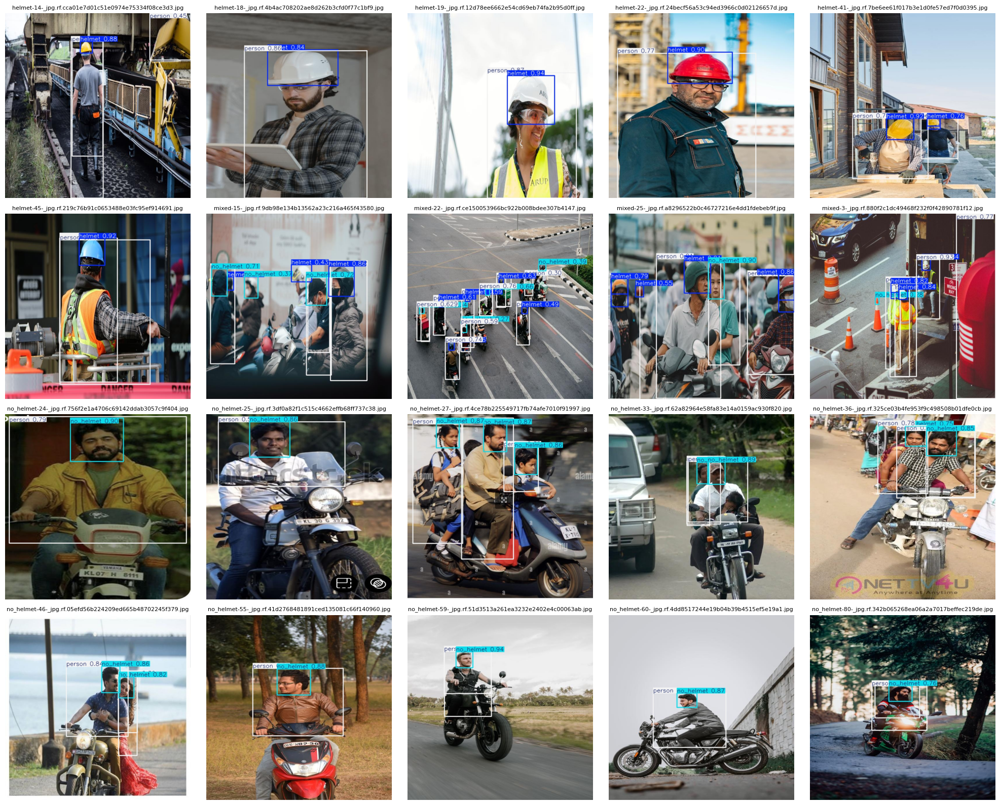

In [11]:
import glob, cv2
from pathlib import Path
DATASET = '/content/dataset'
test_imgs = sorted(glob.glob(f'{DATASET}/images/test/*.*'))
print(len(test_imgs), 'test images')
preds = best.predict(test_imgs, conf=0.25, imgsz=640, save=True, project='/content/runs',
                     name='predictions', exist_ok=True, line_width=2)
PRED_DIR = '/content/runs/predictions'
shown = sorted(glob.glob(f'{PRED_DIR}/*.*'))[:20]
fig, axs = plt.subplots(4, 5, figsize=(20, 16))
for ax, p in zip(axs.ravel(), shown):
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); ax.set_title(Path(p).name, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [12]:
def xywhn_to_xyxy(x, y, w, h, W, H):
    return [(x - w/2)*W, (y - h/2)*H, (x + w/2)*W, (y + h/2)*H]

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/ua if ua > 0 else 0

rows = []
for r in preds:
    H, W = r.orig_shape
    gt = []
    for line in open(f'{DATASET}/labels/test/{Path(r.path).stem}.txt').read().splitlines():
        c, x, y, w, h = line.split()
        gt.append((int(c), xywhn_to_xyxy(float(x), float(y), float(w), float(h), W, H)))
    pr = [(int(b.cls), b.xyxy[0].tolist()) for b in r.boxes]
    used, fn, wrong, tp = set(), 0, 0, 0
    for gc, gb in gt:
        bj, bi = -1, 0.0
        for j, (pc, pb) in enumerate(pr):
            if j in used: continue
            v = iou(gb, pb)
            if v > bi: bi, bj = v, j
        if bi >= 0.5:
            used.add(bj)
            if pr[bj][0] == gc: tp += 1
            else: wrong += 1
        else:
            fn += 1
    fp = len(pr) - len(used)
    rows.append({'image': Path(r.path).name, 'gt_boxes': len(gt), 'TP': tp, 'FN(missed)': fn,
                 'FP(extra)': fp, 'wrong_class': wrong, 'errors': fn + fp + wrong})
err_df = pd.DataFrame(rows).sort_values('errors', ascending=False)
display(err_df.head(15))
print('Totals -> FN:', err_df['FN(missed)'].sum(), 'FP:', err_df['FP(extra)'].sum(), 'wrong class:', err_df['wrong_class'].sum())

,image,gt_boxes,TP,FN(missed),FP(extra),wrong_class,errors
7,mixed-22-_jpg.rf.ce150053966bc922b008bdee307b4...,26,10,15,9,1,25
6,mixed-15-_jpg.rf.9db98e134b13562a23c216a465f43...,10,7,2,2,1,5
9,mixed-3-_jpg.rf.880f2c1dc49468f232f0f42890781f...,6,6,0,4,0,4
8,mixed-25-_jpg.rf.a8296522b0c46727216e4dd1fdebe...,8,8,0,3,0,3
13,no_helmet-33-_jpg.rf.62a82964e58fa83e14a0159ac...,4,3,1,2,0,3
0,helmet-14-_jpg.rf.cca01e7d01c51e0974e75334f08c...,2,2,0,2,0,2
15,no_helmet-46-_jpg.rf.05efd56b224209ed665b48702...,3,3,0,2,0,2
12,no_helmet-27-_jpg.rf.4ce78b225549717fb74afe701...,6,5,1,1,0,2
20,no_helmet-86-_jpg.rf.c2241722c4bca92f03637f952...,2,2,0,1,0,1
4,helmet-41-_jpg.rf.7be6ee61f017b3e1d0fe57ed7f0d...,4,4,0,1,0,1


Totals -> FN: 19 FP: 31 wrong class: 2


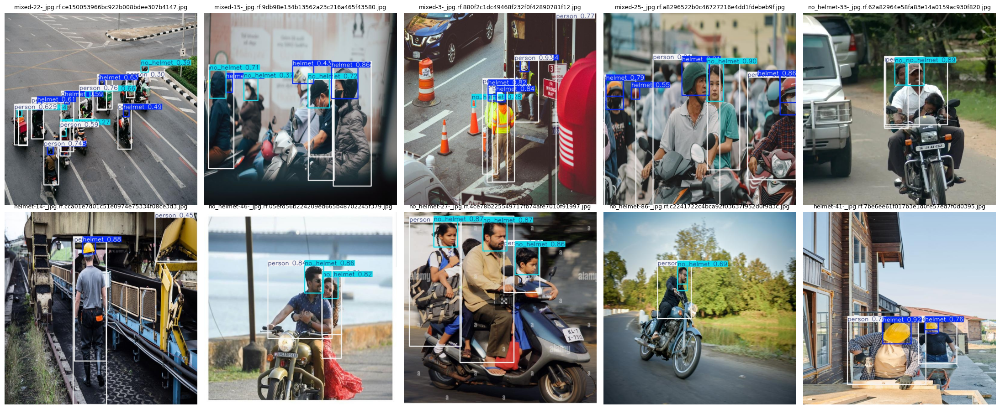

In [13]:
worst = err_df.head(10)['image'].tolist()
fig, axs = plt.subplots(2, 5, figsize=(22, 9))
for ax, n in zip(axs.ravel(), worst):
    ax.imshow(cv2.cvtColor(cv2.imread(f'{PRED_DIR}/{n}'), cv2.COLOR_BGR2RGB)); ax.set_title(n, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

In [14]:
import json
summary = {'gpu': GPU_NAME, 'epochs': EPOCHS, 'imgsz': IMGSZ, 'batch': BATCH,
           'training_minutes': round(train_secs/60, 1),
           'val_metrics': val_table.to_dict('records'), 'test_metrics': test_table.to_dict('records')}
json.dump(summary, open('/content/runs/summary.json', 'w'), indent=2)
OUT_DRIVE = f'{ROOT}/outputs'
os.makedirs(OUT_DRIVE, exist_ok=True)
shutil.copy(f'{RUN}/weights/best.pt', f'{OUT_DRIVE}/best.pt')
shutil.copytree('/content/runs', f'{OUT_DRIVE}/runs', dirs_exist_ok=True)
err_df.to_csv(f'{OUT_DRIVE}/error_analysis_auto.csv', index=False)
print(os.listdir(OUT_DRIVE))

['best.pt', 'runs', 'error_analysis_auto.csv']


In [15]:
m2 = YOLO('yolov8s.pt')
t1 = time.time()
m2.train(data='/content/data.yaml', epochs=50, imgsz=640, batch=16, patience=20,
         project='/content/runs', name='helmet_v8s', exist_ok=True, seed=42)
print(f'YOLOv8s training time: {(time.time()-t1)/60:.1f} min')
best_s = YOLO('/content/runs/helmet_v8s/weights/best.pt')
ms = best_s.val(data='/content/data.yaml', split='test', imgsz=640)
print('YOLOv8s TEST -> precision', round(ms.box.mp, 3), 'recall', round(ms.box.mr, 3),
      'mAP50', round(ms.box.map50, 3), 'mAP50-95', round(ms.box.map, 3))
shutil.copytree('/content/runs', f'{ROOT}/outputs/runs', dirs_exist_ok=True)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_v8s, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

'/content/drive/MyDrive/airi_helmet/outputs/runs'